### ***PDE's Analyize Methods***

- POD 本征正交分解
- DMD 动力学模态分解
- Global Unstability 全局不稳定性分析
- Resolvant 预解分析

In [ ]:
import sys
import solver1D
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
print('if you see this token,the notebook is ready')

if you see this token,the notebook is ready


0. 首先调用一次一维声波求解器,观察在出现扰动情况下声波的传递现象

N = 400, dx = 2.5000e-03 m, dt = 4.2357e-06 s, steps = 945
t = 4.0000e-03 s, snapshots = 8
the history data is saved to history.csv,solution is finished in 16.021573305130005s


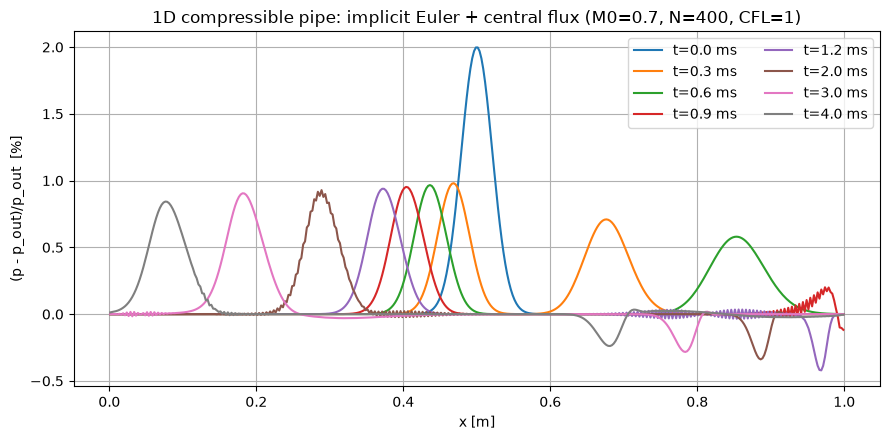

In [2]:
ma,T,p0,L,N = 0.7,300,1e5,1,400
sol = solver1D.flowsolve(ma,T,p0,L,N)
sol.solve()
sol.plot()

上图只是显示了运行时声波脉动谱 $\frac{p-p_{out}}{p_{out}}$ ,将其可视化为一个云图

- 云图中可见一道红色波和一道蓝色波,即为向两侧传播的声波.
- 由于在中心处出现了一处原始压力扰动,这个压力扰动将引发流动失稳,在两侧有反射的边界形成反射的声波,并被保留在这个一维的结构中.
- 在图中可以拟合出波的运行速度,这个运行速度和基于特征线理论的 $ u \pm c$ 是匹配的

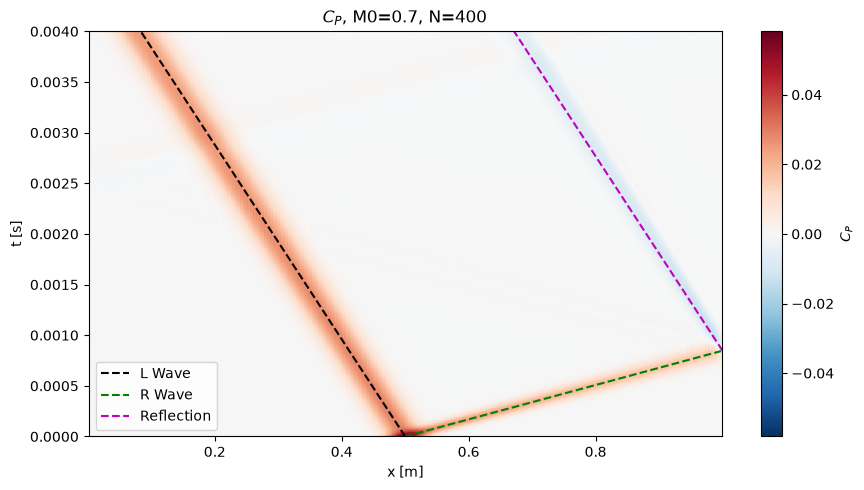

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

df = pd.read_csv(sol.csvname)
t = df.iloc[:, 0].to_numpy()
x = np.array([float(s.split('=')[1]) for s in df.columns[1:]])
p = df.iloc[:, 1:].to_numpy()
Cp = (p - sol.p_out) / (0.5 * sol.rho0 * sol.M0**2 * sol.gamma * sol.Rgas * sol.T0)
vmax = np.abs(Cp).max()
norm = TwoSlopeNorm(vmin=-vmax, vcenter=0.0, vmax=vmax)

# CFD results by solver1D
fig, ax = plt.subplots(figsize=(9, 5))
pc = ax.pcolormesh(x, t, Cp, shading='auto', cmap='RdBu_r', norm=norm)
ax.set_xlabel('x [m]')
ax.set_ylabel('t [s]')
ax.set_title(r'$C_P$, ' f'M0={sol.M0:g}, N={len(x)}')
ax.set_xlim(x[0], x[-1])
ax.set_ylim(t[0], t[-1])

# Theory solution By Riemann
ax.plot(0.5 * sol.L + (sol.u0 - sol.c0) * t, t, 'k--', lw=1.5, label=r'L Wave')
ax.plot(0.5 * sol.L + (sol.u0 + sol.c0)  * t[t <= (sol.L - 0.5 * sol.L) / (sol.u0 + sol.c0)], 
        t[t <= (sol.L - 0.5 * sol.L) / (sol.u0 + sol.c0)], 'g--', lw=1.5, label=r'R Wave')
ax.plot(sol.L + (sol.u0 - sol.c0) * (t[t >= (sol.L - 0.5 * sol.L) / (sol.u0 + sol.c0)] - (sol.L - 0.5 * sol.L) / (sol.u0 + sol.c0)), 
        t[t >= (sol.L - 0.5 * sol.L) / (sol.u0 + sol.c0)], 'm--', lw=1.5, label='Reflection')
ax.legend(loc='lower left')

cb = fig.colorbar(pc, ax=ax)
cb.set_label(r'$C_P$')
fig.tight_layout()
plt.show()